# Assignment 2: Logistic Regression 

**Overview:**

In this assignment, you will conduct two additional analyses of the Columbia Speed Dating Experiment using logistic regression.
1. Test whether the associations between profile features (e.g., demographic variables and trait ratings) and sending a like differ by gender.
2. Test whether an overconfidence proxy is associated with receiving a like.

**Instructions:**

1. Put all written answers in the markdown cells below the question statement.
2. Keep code output.
3. Each group submits 1 notebook. 
 

## Set up dataset

Cell output is not required
<h4 style="color:blue">Complete the code cells below:</h4> 

In [26]:
#======== Load Package: 
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF

from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize,
                         poly)


from ISLP import confusion_table

In [27]:

#load data
dating=pd.read_csv('SpeedDatingData.csv', encoding="ISO-8859-1")

#drop waves  6,7,8,9 and rename the dataset as dating
dating =dating[~dating['wave'].isin([6, 7, 8, 9])]


In [28]:
#====== Extract Relavant Vars:
pre_cols = [
    "iid", "gender", "age",  
    # self-eval (pre-survey)
    "attr3_1", "intel3_1", "sinc3_1", "fun3_1", 
     # partner-eval (date)
    "attr_o", "sinc_o", "intel_o","fun_o", 
    #eval of partner
    "attr","sinc","intel","fun",
    # match data (dating outcome)
      "dec","dec_o" ]

dating_sample=dating[pre_cols]

### Task 0: General Information of the Data

1. Report the total # of rows with missing values (cell output)
2. For each variable, compute the  total # of missing values and the percentage of missing values in the same table (cell output)

<h4 style="color:blue">Please complete the code cells below:</h4> 

In [29]:
#====== Check Missing Values for 'dating_sample':

#compute total # of rows with missing value
missing_total=dating_sample.isna().any(axis=1).sum()

#compute total # of row
total_record=dating_sample.shape[0]

#output
print('Out of', total_record, 'records', missing_total,'are missing')

Out of 6816 records 751 are missing


In [30]:
#----- closer look at missing

#total # of missing values within each variable
missing_counts = dating_sample.isnull().sum()

# calculate ratio (proportion of missing values)
missing_ratio = dating_sample.isnull().mean()

# combine missing_counts, calculate ratio (as two columns) into a summary table
missing_summary = pd.DataFrame({
    'MissingCount': missing_counts,
    'MissingRatio': missing_ratio
}).sort_values(by='MissingRatio', ascending=False)

#output
missing_summary[0:10]

,MissingCount,MissingRatio
fun_o,305,0.044748
fun,295,0.043281
intel_o,276,0.040493
intel,266,0.039026
sinc_o,263,0.038586
sinc,253,0.037119
attr_o,204,0.029930
attr,194,0.028462
attr3_1,100,0.014671
intel3_1,100,0.014671


In [31]:
#Drop the missing variables and name the new dataset as dating_sample_0
dating_sample_0=dating_sample.dropna()

print('Rows after dropping missing values:', dating_sample_0.shape[0])

Rows after dropping missing values: 6065


##  Task 1: 

### We are curious about: 
Whether the correlations between profile features (e.g., demographic vars, traits rating) and 'sending a like' differs by gender.

#### Question 1.1: Write down the regression model you would try first.

 

  <h4 style="color:blue">(Write your answer here)</h4>


 

Our first model is a logistic regression with dec as the outcome. Since we want to know if the effect of each feature is different for men and women, we include gender, each feature, and an interaction between gender and each feature:

log odds of dec ~ gender + age + attr + sinc + intel + fun + gender:age + gender:attr + gender:sinc + gender:intel + gender:fun

$$
\log\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 gender + \beta_2 age + \beta_3 attr + \beta_4 sinc + \beta_5 intel + \beta_6 fun
$$
$$
+ \beta_7 (gender \times age) + \beta_8 (gender \times attr) + \beta_9 (gender \times sinc) + \beta_{10} (gender \times intel) + \beta_{11} (gender \times fun)
$$

where p = P(dec = 1), the probability that the participant says yes to their partner.

Gender is coded 0 for female and 1 for male, so women are the reference group. That means β2 to β6 give the effect of each feature for women, and the interaction terms (β7 to β11) show how much that effect changes for men. For example, the effect of attractiveness is β3 for women and β3 + β8 for men. If an interaction term is significant, the feature matters differently for men and women.

---

#### Question 1.2: In this model, which variables are numerical / nominal 

<h4 style="color:blue">(Write your answer here)</h4>

Numerical variables: age, attr, sinc, intel and fun. Age is the participant's age in years, and attr, sinc, intel and fun are the participant's ratings of their partner on a 1 to 10 scale. Like in Lab 4, we treat the ratings as numerical, since a higher score means the participant rated the partner higher on that trait. The interaction terms (gender:age, gender:attr, gender:sinc, gender:intel, gender:fun) are also numerical. They are the feature value for men and 0 for women.

Nominal variables: gender and dec. Gender has two categories (0 = female, 1 = male), and since it is already coded as 0/1 it goes into the model as a dummy variable with women as the reference group. The outcome dec is also nominal: 1 if the participant said yes to the partner and 0 if they said no. Because the outcome is binary, we use logistic regression instead of linear regression.

---
#### Question 1.3: Please complete the regression

1. Report the **`significant` regression coefficient(s)**, and their **p-value** in the cell output 
2. Report the  **`insignificant` regression coefficient(s)** in the cell output (use threshold 0.1)
 
<h4 style="color:blue">(Complete the code cells)</h4>


In [32]:
#----- set up the variables: 
# main effects + gender x feature interactions (a tuple in MS creates an interaction term)
design_int = MS(['gender', 'age', 'attr', 'sinc', 'intel', 'fun',
                 ('gender', 'age'), ('gender', 'attr'), ('gender', 'sinc'),
                 ('gender', 'intel'), ('gender', 'fun')], intercept=True)


#-------model specification and estimation
X_int = design_int.fit_transform(dating_sample_0)
y_int = dating_sample_0['dec']

#------ get result
glm_int = sm.GLM(y_int, X_int, family=sm.families.Binomial()).fit()

#---- result summary
glm_int_summary=summarize(glm_int)

#---- significant and nonsignificant vars
glm_int_summary_sig=glm_int_summary[glm_int_summary['P>|z|']<0.10]
glm_int_summary_insig=glm_int_summary[glm_int_summary['P>|z|']>=0.10]

#--- report using print('')
print('significant table:\n',glm_int_summary_sig[['coef','P>|z|']])  #significant vars

print('\nnonsignificant table:\n',glm_int_summary_insig[['coef','P>|z|']]) #insignificant vars

# keep the full model for comparison in Q1.4
glm_full = glm_int

significant table:
                 coef  P>|z|
intercept    -5.6961  0.000
gender        1.8470  0.002
attr          0.4431  0.000
intel         0.0725  0.081
fun           0.3410  0.000
gender:age   -0.0529  0.003
gender:attr   0.2006  0.000
gender:intel -0.1724  0.003

nonsignificant table:
                coef  P>|z|
age          0.0061  0.586
sinc        -0.0516  0.132
gender:sinc -0.0635  0.215
gender:fun   0.0085  0.852


---
#### Question 1.4: Please complete the code below 

 Based on the regression results, propose and estimate an appropriate reduced model. Clearly identify which terms you retained or removed and justify each decision. Compare the reduced model with the original model and explain whether your substantive conclusions change.

 
<h4 style="color:blue">(Complete the code cells below)</h4>


In [33]:
#------specify an appropriate reduced model
# drop gender:fun and gender:sinc (p > 0.1); keep all main effects
design_int = MS(['gender', 'age', 'attr', 'sinc', 'intel', 'fun',
                 ('gender', 'age'), ('gender', 'attr'), ('gender', 'intel')], intercept=True)

#-------model specification and estimation
X_int = design_int.fit_transform(dating_sample_0)
y_int = dating_sample_0['dec']

#-------get results
glm_int =sm.GLM(y_int, X_int, family=sm.families.Binomial()).fit()


#---- result summary
glm_int_summary=summarize(glm_int)
print('full reduced-model table:\n', glm_int_summary, '\n')

#--- report using print('')
glm_int_summary_sig=glm_int_summary[glm_int_summary['P>|z|']<0.10]
print('significant table (p < 0.1):\n', glm_int_summary_sig)

full reduced-model table:
                 coef  std err       z  P>|z|
intercept    -5.6646    0.403 -14.039  0.000
gender        1.7727    0.597   2.968  0.003
age           0.0057    0.011   0.508  0.611
attr          0.4464    0.029  15.238  0.000
sinc         -0.0801    0.025  -3.151  0.002
intel         0.0913    0.038   2.412  0.016
fun           0.3444    0.023  15.135  0.000
gender:age   -0.0530    0.018  -3.014  0.003
gender:attr   0.1941    0.043   4.472  0.000
gender:intel -0.2108    0.047  -4.531  0.000 

significant table (p < 0.1):
                 coef  std err       z  P>|z|
intercept    -5.6646    0.403 -14.039  0.000
gender        1.7727    0.597   2.968  0.003
attr          0.4464    0.029  15.238  0.000
sinc         -0.0801    0.025  -3.151  0.002
intel         0.0913    0.038   2.412  0.016
fun           0.3444    0.023  15.135  0.000
gender:age   -0.0530    0.018  -3.014  0.003
gender:attr   0.1941    0.043   4.472  0.000
gender:intel -0.2108    0.047  -4.531  0.

In [34]:
#------ compare reduced model with full model
from scipy import stats

# likelihood-ratio test: H0 = the 2 dropped interaction terms are jointly 0
lr_stat = glm_int.deviance - glm_full.deviance
lr_df = glm_full.df_model - glm_int.df_model
lr_p = stats.chi2.sf(lr_stat, lr_df)

compare_models = pd.DataFrame({
    'Full model': [glm_full.df_model, glm_full.deviance, glm_full.aic],
    'Reduced model': [glm_int.df_model, glm_int.deviance, glm_int.aic]},
    index=['# predictors', 'Deviance', 'AIC']).round(2)
print(compare_models)
print(f"\nLikelihood-ratio test: chi2 = {lr_stat:.3f}, df = {lr_df:.0f}, p-value = {lr_p:.3f}")

# coefficients side by side
coef_compare = pd.DataFrame({'Full coef': glm_full.params, 'Full p': glm_full.pvalues,
                             'Reduced coef': glm_int.params, 'Reduced p': glm_int.pvalues}).round(4)
print('\n', coef_compare)

              Full model  Reduced model
# predictors       11.00           9.00
Deviance         6393.59        6395.13
AIC              6417.59        6415.13

Likelihood-ratio test: chi2 = 1.543, df = 2, p-value = 0.462

               Full coef  Full p  Reduced coef  Reduced p
age              0.0061  0.5865        0.0057     0.6112
attr             0.4431  0.0000        0.4464     0.0000
fun              0.3410  0.0000        0.3444     0.0000
gender           1.8470  0.0023        1.7727     0.0030
gender:age      -0.0529  0.0026       -0.0530     0.0026
gender:attr      0.2006  0.0000        0.1941     0.0000
gender:fun       0.0085  0.8519           NaN        NaN
gender:intel    -0.1724  0.0034       -0.2108     0.0000
gender:sinc     -0.0635  0.2155           NaN        NaN
intel            0.0725  0.0809        0.0913     0.0159
intercept       -5.6961  0.0000       -5.6646     0.0000
sinc            -0.0516  0.1324       -0.0801     0.0016


<h4 style="color:blue">(Write your explanations)</h4>

For the reduced model, we removed the two interaction terms that were not significant at the 0.1 level: gender:fun (p = 0.852) and gender:sinc (p = 0.215). Both p-values are well above 0.1, and the gender:fun coefficient is almost zero (0.0085), so there is no evidence that fun or sincerity matter differently for men and women.

We kept the other three interactions, gender:age (p = 0.003), gender:attr (p < 0.001) and gender:intel (p = 0.003), since they are significant and they are what our research question is about. We also kept gender (p = 0.002), attr (p < 0.001), fun (p < 0.001) and intel (p = 0.081) because they are significant at the 0.1 level.

Two terms were insignificant but we kept them anyway. Age (p = 0.586) stays because gender:age is still in the model. If we removed age, the model would force the age effect for women to be exactly 0, and gender:age would no longer be the difference between men and women. We also kept sinc (p = 0.132) since it is one of the main trait ratings, and once gender:sinc is removed, sinc becomes significant (p = 0.002).

Comparing the reduced model to the full model, the likelihood-ratio test for the two dropped terms gives chi-square = 1.54 with 2 df and p = 0.462, so removing them does not make the fit worse. The AIC also goes down slightly, from 6417.6 to 6415.1, which supports the simpler model. The coefficients that were significant before barely change (for example, attr goes from 0.443 to 0.446 and gender:attr from 0.201 to 0.194), and they keep the same signs.

Our conclusions do not change. In both models, attractiveness and fun have the biggest effect on saying yes, the effects of attractiveness, intelligence and age differ by gender, and fun and sincerity work the same way for men and women. The main difference is that sinc (p goes from 0.132 to 0.002) and intel (p goes from 0.081 to 0.016) become more significant once the extra interaction terms are removed.

### Question 1.5 — Observation & Interpretation

**a) Model refinement.**  
If you remove insignificant predictors (if any), briefly describe what has changed (coefficients, fit, key conclusions). 



**b) Interpret significant coefficients.**  

Hint:
- **Sign** (direction of effect)  
- **Magnitude** 
- **Plain-English meaning** 



**c) Hypothesis test (choose one significant coefficient).**  
State the hypotheses and interpret the p-value.

Hint:
- Variable: `_____`  
- **Null (H₀):** 
- **Alternative (H₁):** 
- p-value: `_____`  
- Interpretation of p-value (in text):  



**d) Do effects differ by gender?**  
Hint: Use your regression model to respond:

> **Do the correlations between profile features and 'sending a like' differ by gender?**

 
<h4 style="color:blue">(Write your answer here)</h4>

a)

In the reduced model we removed gender:fun and gender:sinc since they were not significant. Most of the coefficients stayed almost the same, with changes only in the second or third decimal. The two that changed more were sinc (from −0.052 to −0.080) and intel (from 0.073 to 0.091). Both became significant at the 5% level, probably because part of their effect had been picked up by the interaction terms we removed. The fit barely changed: the deviance went from 6393.6 to 6395.1, the likelihood-ratio test was not significant (p = 0.462), and the AIC went down from 6417.6 to 6415.1. So we have a simpler model with two fewer terms that fits just as well, and our main conclusions are the same: the effects of attractiveness, intelligence and age differ by gender, but the effects of fun and sincerity do not.

b)

Since gender is coded 0 = female and 1 = male, the main effect of each feature is the effect for women, and the effect for men is the main effect plus the interaction. All interpretations hold the other variables constant. The percent change in odds is calculated as (e^β − 1) × 100.

attr (0.446): For women, a one-point higher attractiveness rating is associated with a 0.446 increase in the log-odds of saying yes (odds increase by about 56%).

gender:attr (0.194): The effect of attractiveness is 0.194 higher for men, so for men the coefficient is 0.446 + 0.194 = 0.640. A one-point higher attractiveness rating increases men's odds of saying yes by about 90%. Attractiveness matters for both genders, but more for men.

fun (0.344): A one-point higher fun rating is associated with a 0.344 increase in the log-odds of saying yes (odds increase by about 41%). Since we removed gender:fun, this is the same for men and women. After attractiveness, fun has the biggest effect.

intel (0.091): For women, a one-point higher intelligence rating is associated with a 0.091 increase in the log-odds of saying yes (odds increase by about 10%).

gender:intel (−0.211): The effect of intelligence is 0.211 lower for men, so for men the coefficient is 0.091 − 0.211 = −0.120. For men, a one-point higher intelligence rating is associated with about an 11% decrease in the odds of saying yes. So holding attractiveness and fun constant, women are more likely to say yes to partners they rate as more intelligent, while men are slightly less likely to.

sinc (−0.080): A one-point higher sincerity rating is associated with a 0.080 decrease in the log-odds of saying yes (odds decrease by about 8%) for both men and women. The effect is small. One possible reason is that a partner who is rated as sincere but not very attractive or fun is still often a "no".

gender:age (−0.053): Age is not significant for women (coefficient 0.006, p = 0.61). For men the age coefficient is 0.006 − 0.053 = −0.047, so each extra year of a man's age is associated with about a 4.6% decrease in his odds of saying yes. Older men in the sample were more selective.

gender (1.773): This is the difference in log-odds between men and women when age and all ratings are 0, which is not a realistic case, so we should not interpret it by itself. The gender differences mostly come from the interaction terms.

intercept (−5.665): This is the log-odds of saying yes for a woman who is 0 years old and gives all ratings of 0. It does not have a practical meaning.

c)

Variable: gender:attr

H₀: β(gender:attr) = 0. The effect of attractiveness on saying yes is the same for men and women.

H₁: β(gender:attr) ≠ 0. The effect of attractiveness on saying yes is different for men and women.

p-value: 7.7e-06 (shown as 0.000 in the output, z = 4.47)

Interpretation: If attractiveness had the same effect for men and women, the probability of getting a difference this large or larger in our sample would be about 0.0008%. Since this is much smaller than 0.05, we reject H₀. There is strong evidence that attractiveness affects men's decisions more than women's (0.640 for men vs 0.446 for women).

d)

Partly yes. Some features affect men and women differently, but not all of them.

- Attractiveness: different. It matters for both, but more for men (about +90% odds per point for men vs +56% for women, gender:attr p < 0.001).
- Intelligence: different, and in the opposite direction. Higher intelligence ratings increase women's odds of saying yes (+10%) but slightly decrease men's (−11%), with gender:intel p < 0.001.
- Age: different. Older men are less likely to say yes (−4.6% odds per year), while age does not matter for women (gender:age p = 0.003).
- Fun and sincerity: not different. The interaction terms were not significant (p = 0.85 and 0.22), so we removed them. Fun increases the odds of saying yes for everyone (+41%), and sincerity slightly decreases them (−8%).

Overall, both men and women care most about attractiveness and fun, but men put more weight on attractiveness and less on intelligence than women do.

### Question 1.6 — Prediction Accuracy

Please use the last model to predict the outcomes (sending like) and in the cell output, please report  

1. accuracy rate
2. confusion table
3. ROC curve
4. AUC

<h4 style="color:blue">(Complete the code cells below)</h4>

In [35]:
#========= get probability of sending yes for each date
probs = glm_int.predict(X_int)

In [36]:
#=========set a threshold (=0.5) to make prediction
threshold=0.5
labels = np.where(probs > threshold, 1, 0)

In [37]:
#==========generate confusion matrix

cm = confusion_table(labels, y_int)

#output
cm

Truth,0,1
Predicted,,
0,2697,841
1,748,1779


In [38]:
#======= compute accuracy
tn, fn, fp, tp = cm.to_numpy().ravel()   # unpack confusion matrix (rows = predicted, columns = truth)

accuracy = (tp + tn) / (tp + tn + fp + fn)


#output
print(f"Accuracy:    {accuracy:.3f}")


Accuracy:    0.738


AUC: 0.810


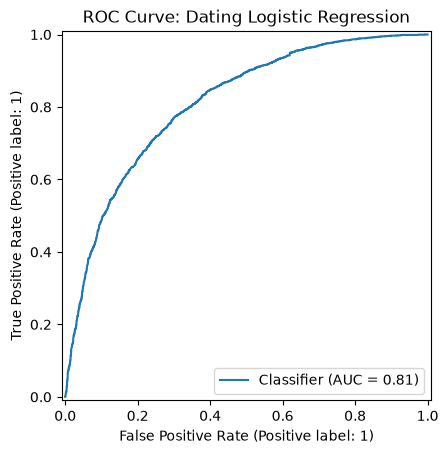

In [39]:
#========= ROC curve

from sklearn.metrics import RocCurveDisplay, roc_auc_score
import matplotlib.pyplot as plt

#----- compute AUC
auc = roc_auc_score(y_int, probs)

print(f"AUC: {auc:.3f}")

#-----draw the graph
RocCurveDisplay.from_predictions(y_int, probs)

#-----add title
plt.title("ROC Curve: Dating Logistic Regression")
plt.show()

Using the reduced model with a threshold of 0.5, the confusion table gives 2697 true negatives, 748 false positives, 841 false negatives and 1779 true positives (rows are predicted, columns are the actual decisions).

The accuracy is 0.738, so the model correctly predicts about 74% of the decisions. Since only 43.2% of the decisions in our data are "yes", just predicting "no" every time would give an accuracy of 56.8%, so our model does a lot better than that. The model correctly predicts 67.9% of the actual "yes" decisions (1779 / 2620) and 78.3% of the actual "no" decisions (2697 / 3445), so it is a bit better at predicting "no" than "yes".

The AUC is 0.810. This means that if we pick one date where the participant said yes and one where they said no, the model gives a higher probability to the "yes" date about 81% of the time. The ROC curve is well above the diagonal line, which is what a random guess would give, so the model separates yes and no decisions quite well.

One limitation is that we tested the model on the same data we used to fit it, so these numbers are probably a little higher than they would be on new data. Splitting the data into a training set and a test set would give a better estimate.

## Task 2: 

### We are curious about:

Whether an **overconfidence proxy** is associated with **receiving a like**.

For each selected trait (e.g., sincerity), we define the overconfidence proxy as:

`<trait>_gap = self-rating of the trait − partner’s rating of the trait`

A positive gap indicates that the participant rated themselves more highly than their partner did. We will examine whether these trait-gap variables, together with other relevant factors such as gender and the partner’s ratings, are associated with whether the participant **receives a like from their partner**.

**Be careful:** This outcome is not whether the participant sends a like.

### Question 2.1: 

Please follow the hint in the code cell below to create the  `< trait >_gap` variable for each trait and create a new dataset `dating_sample_gap`for analysis.  Report the first 10-15 rows of this dataset in the cell output

*HINT:* Please read the variable decription (word doc in assignment folder) carefully to make sure you select the correct variables.  
 
<h4 style="color:blue">(Complete the code cells)</h4>

In [40]:
#----create copy of the processed dataset
dating_sample_gap=dating_sample_0.copy()


#----group the variables
self_var=[...]
other_val=[...]


# create <base>_gap columns: <base>_gap = self - other (of course, this is just one way to do so)
bases = ["attr", "intel", "sinc", "fun"]

for b, s, o in zip(bases, self_var, other_val):
    dating_sample_gap[b + "_gap"] = dating_sample_gap[s] - dating_sample_gap[o]

#output
dating_sample_gap[0:10]

KeyError: Ellipsis

### Question 2.2: 

Please draw the bar chart to compare the mean of '_gap' between genders. Report the graph in the cell output. 
 
<h4 style="color:blue">(Complete the code cells)</h4>

In [ ]:
#------get mean of gap, group by gender
gap=dating_sample_gap.groupby(...)[].mean().T


#rename the columns of 'gap' table
gap.columns=['Female','Male']

#---- plot 
gap.plot(kind="bar", figsize=(10,7))
plt.title("Gender Comparison: Mean Trait Gaps by Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

### Question 2.3

We will examine which factors are associated with whether a participant **receives a like from their partner**. What is the dependent variable in this regression? Write the variable name and briefly explain why it represents receiving, rather than sending, a like.

<h4 style="color:blue">(Write your answer here)</h4>

### Question 2.4: 

In addition to the partner ratings and the trait-gap variables, what other explanatory variables would you include? Specify your regression model and justify your choices.
 

<h4 style="color:blue">(Write your answer here)</h4>

### Question 2.5: Please complete the regression

Estimate the logistic regression model that you proposed in Question 2.4 and display the complete regression output.

Using a significance level of 5%:

1. Report the coefficient estimate and p-value for each trait-gap variable.
2. Identify the statistically significant terms in the model.
3. For each significant term, indicate whether its estimated association with receiving a like is positive or negative.

<h4 style="color:blue">(Complete the code cells below)</h4>

In [ ]:
#======== predict dec_o (receiving likes)

#--- create the name list for predictors
num_cols = [...]

dating_sample_gap[num_cols] = dating_sample_gap[num_cols].apply(pd.to_numeric, errors="coerce")


#--- regression
design_overc = MS(...)

X_overc = design_overc.fit_transform(...)
y_overc = dating_sample_gap[...]

glm_overc = sm.GLM(...).fit()

#--- Results summary
glm_overc_summary=...
glm_overc_summary_sig=...

#---output
print(...)

### Question 2.6 — Interpretation and Critical Evaluation

**a) Interpret the statistically significant coefficients.**

For each significant coefficient, discuss:

- **Sign:** Is the estimated association positive or negative?
- **Magnitude:** Magnitudes of coefficients?
- **Plain-English:** What does the result mean in the context?


**b) Conduct a hypothesis test for one statistically significant variable.**

State the hypotheses and interpret the p-value.

- Variable: `_____`
- **Null hypothesis (H₀):**
- **Alternative hypothesis (H₁):**
- p-value: `_____`
- Conclusion at the 5% significance level:
- Interpretation in context:

**c) Does the overconfidence proxy matter?**

Use the results for all trait-gap variables to evaluate whether the overconfidence proxy is associated with receiving a like. Is the evidence consistent across traits, or is it limited to particular traits? Explain your conclusion.

**d) Evaluate the use of this model.**

Could this model be used to predict whether a participant will receive a like **before the date occurs**? Identify the relevant variables and explain your answer.

<h4 style="color:blue">(Write your answers here)</h4>

a)

b)

c)

d)

### Question 2.7 — Independent Model Extension and Reflection

Please propose **one meaningful extension** to the regression model used in Question 2.5. There is no single correct extension.


Do not select an extension simply because it produces a statistically significant result.

**a) Motivation**

Describe your proposed extension. What question does it help you investigate, and why is it relevant? Before estimating the model, explain what result you expect and why.

**b) Implementation**

Estimate the extended model. Clearly report:

- the regression;
- the modification you made;
- the relevant coefficient estimates and p-values; and
- any additional output needed to evaluate your extension.


In [ ]:
# write your code here

**c) Comparison**

Compare the extended model with your original model from Question 2.5. Identify at least two results that changed—or remained stable—and explain why you think this occurred.

**d) Conclusion**

What did your group learn from this extension? Explain whether it changes your conclusion about the relationship between the overconfidence proxy and receiving a like.

**e) Limitation**

Identify one limitation that is specific to your chosen extension. Explain what additional data or analysis would help address it.

Your grade will be based on the logic connecting your research question, modeling choice, results, and interpretation—not on whether your extension produces statistically significant findings.

<h4 style="color:blue">(Rrite your answers below)</h4>



c)

d)

e)